In [42]:
import pandas as pd
import scipy.stats
import umap
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
import torch
import os
import sys
from pathlib import Path
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.ndimage import gaussian_filter
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
from matplotlib.ticker import MaxNLocator
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [43]:
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
#pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]

In [44]:
pseudo_response_tensor.shape

(128, 2, 100, 11270)

In [45]:

def iso_ae_preprocessing(pseudo_response_tensor):
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])

    X_transposed = response_matrix.T

    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)

    # Reduce features to 20 using PCA

    return X_pre_pca

X_input = iso_ae_preprocessing(pseudo_response_tensor)

In [46]:
def calculate_msd(response_matrix):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    response_matrix_expand = response_matrix.reshape( response_matrix.shape[0],100,2)
    diff_responses = np.diff(response_matrix_expand, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
    msd = np.mean(np.abs(diff_responses), axis=(1, 2))
    return msd

msd_data = calculate_msd(X_input)


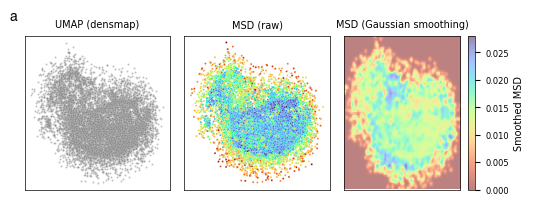

In [47]:
# Plot densmap projection of EID responses
#Figure 1
fig = plt.figure(figsize=(6, 2))
gs = gridspec.GridSpec(1, 3)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])
ax3 = plt.subplot(gs[0,2])

# First row
#from sklearn.manifold import Isomap
z_neurons = umap.UMAP(densmap=True,dens_lambda=2,n_neighbors = 500).fit_transform(X_input)
#z_neurons = Isomap(n_neighbors=100).fit_transform(X_input)

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], color = 'gray',ax=ax1,s=2,legend=False,alpha =.5)
ax1.text(-0.1, 1.1, 'a', transform=ax1.transAxes, fontsize=10, fontweight='bold', fontfamily='helvetica')
ax1.set_title('UMAP (densmap)')
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xticklabels([])
ax1.set_yticklabels([])

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = msd_data,ax=ax2,palette='turbo',s=2,legend=False)
ax2.set_title('MSD (raw)')
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xticklabels([])
ax2.set_yticklabels([])

# Smoothed MSD coloring
# Create a grid for Gaussian smoothing
grid_size = 100
xi = np.linspace(z_neurons[:, 0].min(), z_neurons[:, 0].max(), grid_size)
yi = np.linspace(z_neurons[:, 1].min(), z_neurons[:, 1].max(), grid_size)
xi, yi = np.meshgrid(xi, yi)

# Use a 2D histogram to bin the msd_data
from scipy.stats import binned_statistic_2d
bin_means, x_edges, y_edges, _ = binned_statistic_2d(
    z_neurons[:, 0], z_neurons[:, 1], msd_data, 
    statistic='mean', bins=grid_size
)

# Replace NaNs with 0 for smoothing (or interpolate)
bin_means[np.isnan(bin_means)] = 0
smoothed_msd = gaussian_filter(bin_means, sigma=1)

im = ax3.imshow(
    smoothed_msd.T, extent=[z_neurons[:, 0].min(), z_neurons[:, 0].max(), z_neurons[:, 1].min(), z_neurons[:, 1].max()],
    origin='lower', cmap='turbo_r', aspect='auto',alpha = .5
)
ax3.set_title('MSD (Gaussian smoothing)')
ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_xticklabels([])
ax3.set_yticklabels([])
plt.colorbar(im, ax=ax3, label='Smoothed MSD')

fig.subplots_adjust(wspace=0.1, hspace=0.1)
#plt.tight_layout()
output_path = Path('BWM/Figures/UMAP_MSD_Overview.png')
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, bbox_inches='tight', dpi=300)
plt.show()


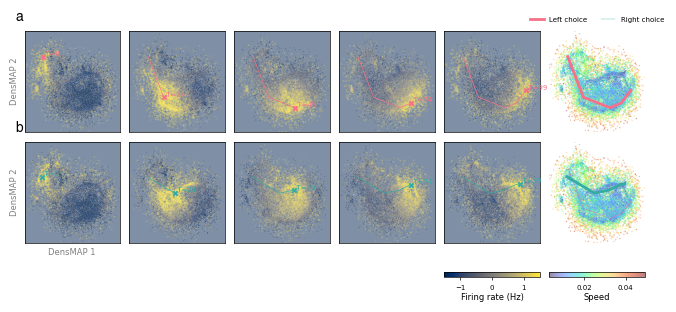

In [72]:
# 2x6 grid of subplots for smoothed neural activity and trajectories
activity_tensor = np.mean(pseudo_response_tensor, axis=0)
activity_tensor = (activity_tensor - np.mean(activity_tensor,axis = (0,1)))/np.std(activity_tensor,axis = (0,1))
n_conds, n_times, n_neurons = activity_tensor.shape

# Parameters
t_start = 0 # Start time index for analysis
traj_step = 1 # Temporal step for trajectory plotting

# Pre-calculate everything needed for all conditions
all_smoothed_activity_3d = []
all_peak_trajectories = []

grid_size = 100
extent = [z_neurons[:, 0].min(), z_neurons[:, 0].max(), z_neurons[:, 1].min(), z_neurons[:, 1].max()]
x_coords = np.linspace(extent[0], extent[1], grid_size)
y_coords = np.linspace(extent[2], extent[3], grid_size)
xv, yv = np.meshgrid(x_coords, y_coords, indexing='ij')

for i in range(n_conds):
    # 1. Build the full 3D activity tensor (x, y, t)
    activity_3d = np.zeros((grid_size, grid_size, n_times))
    for t in range(n_times):
        activity = activity_tensor[i, t, :]
        bin_means, _, _, _ = binned_statistic_2d(
            z_neurons[:, 0], z_neurons[:, 1], activity, 
            statistic='mean', bins=grid_size,
            range=[[extent[0], extent[1]], [extent[2], extent[3]]]
        )
        bin_means[np.isnan(bin_means)] = 0
        activity_3d[:, :, t] = bin_means
    
    # 2. Apply 2D Gaussian smoothing to each time point (kept for trajectory calculation)
    smoothed_activity_3d = np.zeros_like(activity_3d)
    for t in range(n_times):
        smoothed_activity_3d[:, :, t] = gaussian_filter(activity_3d[:, :, t], sigma=1)
    
    # 3. Extract raw peak trajectory (sub-pixel)
    peak_trajectory = []
    window_size = 10
    for t in range(n_times):
        smoothed_activity = smoothed_activity_3d[:, :, t]
        if np.max(smoothed_activity) > 0:
            max_idx = np.unravel_index(np.argmax(smoothed_activity), smoothed_activity.shape)
            x_min = max(0, max_idx[0] - window_size)
            x_max = min(grid_size, max_idx[0] + window_size + 1)
            y_min = max(0, max_idx[1] - window_size)
            y_max = min(grid_size, max_idx[1] + window_size + 1)
            local_weights = smoothed_activity[x_min:x_max, y_min:y_max]
            local_xv = xv[x_min:x_max, y_min:y_max]
            local_yv = yv[x_min:x_max, y_min:y_max]
            peak_x = np.sum(local_xv * local_weights) / np.sum(local_weights)
            peak_y = np.sum(local_yv * local_weights) / np.sum(local_weights)
            peak = np.array([peak_x, peak_y])
        else:
            peak = np.array([np.nan, np.nan])
        peak_trajectory.append(peak)
    
    peak_trajectory = np.array(peak_trajectory)
    
    all_smoothed_activity_3d.append(smoothed_activity_3d)
    all_peak_trajectories.append(peak_trajectory)

# Calculate global vmax for consistent color scale (after t_start)
#global_vmax = np.max([np.max(a[:, :, t_start:]) for a in all_smoothed_activity_3d])
global_vmin = -1.5
global_vmax = 1.5
bg_alpha = 0.5  # Background transparency
cmapname = 'Spectral'
activity_cmap = plt.get_cmap(cmapname)
bg_color = activity_cmap(0.0)  # Low end of the colormap
# Select 5 time points for snapshots starting from t_start
time_indices = np.linspace(t_start, n_times - 1, 5, dtype=int)

# Use husl colormap for trial conditions
cond_colors = sns.color_palette("husl", n_conds)

fig, axes = plt.subplots(2, 6, figsize=(8, 2.75), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.1, hspace=0.1)

# Common limits
x_lims = [extent[0], extent[1]]
y_lims = [extent[2], extent[3]]

for i in range(n_conds):
    smoothed_activity_3d = all_smoothed_activity_3d[i]
    peak_trajectory = all_peak_trajectories[i]
    
    for j in range(6):
        ax = axes[i, j]
        if i == 0 and j == 0:
             ax.text(-0.1, 1.1, 'a', transform=ax.transAxes, fontsize=10, fontweight='bold', fontfamily='helvetica')
        if i == 1 and j == 0:
             ax.text(-0.1, 1.1, 'b', transform=ax.transAxes, fontsize=10, fontweight='bold', fontfamily='helvetica')
        
        # Set all spines to be visible
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.5)
            spine.set_color('black')

        if j < 5:
            ax.set_facecolor((*bg_color[:3], bg_alpha))
        else:
            ax.set_facecolor('none')
            # ax.axis('off') # Keep spines visible
        ax.set_xlim(x_lims)
        ax.set_ylim(y_lims)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        
        if j == 0:
            ax.set_ylabel('DensMAP 2',fontsize =6, alpha = .5)
            if i ==1:
                ax.set_xlabel('DensMAP 1',fontsize =6, alpha = .5)
        if j < 5:
            # Snapshot of activity
            t_idx = time_indices[j]
            activity = activity_tensor[i, t_idx, :]
            
            # Scatter plot of activity
            sns.scatterplot(
                x=z_neurons[:, 0], y=z_neurons[:, 1], hue=activity, 
                palette=cmapname, s=1, alpha=0.3, zorder=2, ax=ax, legend=False,
                hue_norm=plt.Normalize(global_vmin, global_vmax)
            )

            # Mark peak activity
            ax.scatter(peak_trajectory[t_idx, 0], peak_trajectory[t_idx, 1], color=cond_colors[i], s=10, marker='x', zorder=5)
            ax.text(peak_trajectory[t_idx, 0], peak_trajectory[t_idx, 1], f' T={t_idx}', color=cond_colors[i], fontsize=5, verticalalignment='bottom', zorder=6)
            
            t_traj = time_indices[:j+1]
            ax.plot(peak_trajectory[t_traj, 0], peak_trajectory[t_traj, 1], color=cond_colors[i], linewidth=.5, alpha=1, zorder=4)
            
            if i == 0:
                pass
            
            # Add horizontal color bar under the 5th column (j=4)
            if j == 4 and i == 1:
                cax = inset_axes(
                    ax, width="100%", height="5%",
                    loc="lower center", borderpad=-3.5
                )
                norm = plt.Normalize(global_vmin, global_vmax)
                sm = plt.cm.ScalarMappable(cmap=cmapname, norm=norm)
                cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
                cb.outline.set_linewidth(0.5)
                cax.set_xlabel("Firing rate (Hz)", fontsize=6, labelpad=2)
                cax.xaxis.set_tick_params(labelsize=5, length=2, width=0.5)
        else:
            # Snapshot of activity at t_start
            activity_start = activity_tensor[i, t_start, :]
            sns.scatterplot(
                x=z_neurons[:, 0], y=z_neurons[:, 1], hue=msd_data,
                palette='turbo', s=1, alpha=0.4, zorder=1, ax=ax, legend=False)

            
            # Slice trajectory by step and start time
            t_plot = time_indices
            peak_traj_to_plot = peak_trajectory[t_plot]
            
            # Plot peak trajectory
            ax.plot(peak_traj_to_plot[:, 0], peak_traj_to_plot[:, 1], color=cond_colors[i], linewidth=2, alpha=1, zorder=4, label='Left choice')
            
            # Plot opposite condition trajectory in husl color scheme
            opp_i = 1 - i
            opp_peak_trajectory = all_peak_trajectories[opp_i]
            opp_peak_traj_to_plot = opp_peak_trajectory[t_plot]
            ax.plot(opp_peak_traj_to_plot[:, 0], opp_peak_traj_to_plot[:, 1], color=cond_colors[opp_i], linewidth=0.25, alpha=1, zorder=3, label='Right choice')
            
            # Add legend to the top-right subplot
            if i == 0:
                ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=5, frameon=False)
            
            # Mark start and end of trajectory
            # valid_idx = np.where(~np.isnan(peak_traj_to_plot[:, 0]))[0]
            # if len(valid_idx) > 0:
            #     ax.scatter(peak_traj_to_plot[valid_idx[0], 0], peak_traj_to_plot[valid_idx[0], 1], color='green', s=15, zorder=5)
            #     ax.scatter(peak_traj_to_plot[valid_idx[-1], 0], peak_traj_to_plot[valid_idx[-1], 1], color='red', s=15, zorder=5)
            
            if i == 0:
                pass
            
            # Add horizontal color bar under the 6th column (j=5) for MSD
            if j == 5 and i == 1:
                cax_msd = inset_axes(
                    ax, width="100%", height="5%",
                    loc="lower center", borderpad=-3.5
                )
                norm_msd = plt.Normalize(msd_data.min(), msd_data.max())
                sm_msd = plt.cm.ScalarMappable(cmap="turbo", norm=norm_msd)
                cb_msd = fig.colorbar(sm_msd, cax=cax_msd, orientation="horizontal", alpha=0.5)
                cb_msd.outline.set_linewidth(0.5)
                # cb_msd.ax.set_alpha(0.25) # Set transparency
                cax_msd.set_xlabel("Speed", fontsize=6, labelpad=2)
                cax_msd.xaxis.set_tick_params(labelsize=5, length=2, width=0.5)
        


#plt.tight_layout()
output_path = Path('BWM/Figures/Neural_Activity_Trajectories_CP.png')
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, bbox_inches='tight', dpi=300)
plt.show()


In [49]:
 # Movie of spatiotemporal dynamics
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Re-calculate smoothed activity and peaks for all conditions and time points
all_smoothed_activity = [] # List of (grid_size, grid_size, n_times)
all_peak_trajectories = [] # List of (n_times, 2)

for i in range(n_conds):
    # 1. Build the full 3D activity tensor (x, y, t)
    activity_3d = np.zeros((grid_size, grid_size, n_times))
    for t in range(n_times):
        activity = activity_tensor[i, t, :]
        bin_means, _, _, _ = binned_statistic_2d(
            z_neurons[:, 0], z_neurons[:, 1], activity, 
            statistic='mean', bins=grid_size,
            range=[[extent[0], extent[1]], [extent[2], extent[3]]]
        )
        bin_means[np.isnan(bin_means)] = 0
        activity_3d[:, :, t] = bin_means
    
    # 2. Apply 2D Gaussian smoothing to each time point
    smoothed_activity_3d = np.zeros_like(activity_3d)
    for t in range(n_times):
        smoothed_activity_3d[:, :, t] = gaussian_filter(activity_3d[:, :, t], sigma=1)
    
    # 3. Extract peak trajectory
    peak_trajectory = []
    window_size = 2
    for t in range(n_times):
        smoothed_activity = smoothed_activity_3d[:, :, t]
        if np.max(smoothed_activity) > 0:
            max_idx = np.unravel_index(np.argmax(smoothed_activity), smoothed_activity.shape)
            x_min = max(0, max_idx[0] - window_size)
            x_max = min(grid_size, max_idx[0] + window_size + 1)
            y_min = max(0, max_idx[1] - window_size)
            y_max = min(grid_size, max_idx[1] + window_size + 1)
            local_weights = smoothed_activity[x_min:x_max, y_min:y_max]
            local_xv = xv[x_min:x_max, y_min:y_max]
            local_yv = yv[x_min:x_max, y_min:y_max]
            peak_x = np.sum(local_xv * local_weights) / np.sum(local_weights)
            peak_y = np.sum(local_yv * local_weights) / np.sum(local_weights)
            peak = np.array([peak_x, peak_y])
        else:
            peak = np.array([np.nan, np.nan])
        peak_trajectory.append(peak)
    
    peak_trajectory = np.array(peak_trajectory)
    
    all_smoothed_activity.append(smoothed_activity_3d)
    all_peak_trajectories.append(peak_trajectory)

# Setup Figure for Animation
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.1, hspace=0.1)
time_text = fig.suptitle('', fontsize=12)

# Use husl colormap for trial conditions
cond_colors = sns.color_palette("husl", n_conds)

ims = []
peak_dots = []
traj_lines = []

# Common limits
x_lims = [extent[0], extent[1]]
y_lims = [extent[2], extent[3]]

for i in range(n_conds):
    ax = axes[i]
    ax.set_xlim(x_lims)
    ax.set_ylim(y_lims)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    # Initialize image
    im = ax.imshow(
        np.zeros((grid_size, grid_size)).T, extent=extent,
        origin='lower', cmap='Spectral', aspect='auto', vmin=0, vmax=np.max([np.max(a) for a in all_smoothed_activity])
    )
    ims.append(im)
    
    # Initialize peak marker
    dot, = ax.plot([], [], color=cond_colors[i], marker='x', markersize=10, linestyle='None', zorder=5)
    peak_dots.append(dot)
    
    # Initialize trajectory line
    line, = ax.plot([], [], color=cond_colors[i], linewidth=1, alpha=0.5, zorder=4)
    traj_lines.append(line)
    
    ax.set_title(f'Condition {i}')
    ax.set_xlabel('UMAP 1')
    if i == 0:
        ax.set_ylabel('UMAP 2')

def update(t):
    time_text.set_text(f'Time Step: {t}')
    for i in range(n_conds):
        # Update image
        ims[i].set_data(all_smoothed_activity[i][:, :, t].T)
        
        # Update peak marker
        peak = all_peak_trajectories[i][t]
        if not np.isnan(peak[0]):
            peak_dots[i].set_data([peak[0]], [peak[1]])
        else:
            peak_dots[i].set_data([], [])
            
        # Update trajectory (history up to t)
        traj = all_peak_trajectories[i][:t+1]
        valid = ~np.isnan(traj[:, 0])
        traj_lines[i].set_data(traj[valid, 0], traj[valid, 1])
        
    return ims + peak_dots + traj_lines + [time_text]

ani = FuncAnimation(fig, update, frames=n_times, interval=50, blit=True)
output_movie_path = Path('BWM/Movies/Spatiotemporal_Dynamics.mp4')
output_movie_path.parent.mkdir(parents=True, exist_ok=True)
ani.save(output_movie_path, writer='ffmpeg', fps=20)
plt.close() # Prevent extra static plot

# Display the animation
HTML(ani.to_jshtml())
